<h2><font color="#004D7F" size=6>Módulo 5. Fase de modelado</font></h2>



<h1><font color="#004D7F" size=5>1. Algoritmos de Machine Learning</font></h1>




---

<h2><font color="#004D7F" size=5>Índice</font></h2>
<a id="indice"></a>

* [1. Introducción](#section1)
    * [1.1. Librerías](#section11)
    * [1.2. CSV](#section12)
* [2. Algoritmos de Clasificación](#section2)
    * [2.1. Algoritmos de taxonomía lineal](#section21)
    * [2.2. Algoritmos de taxonomía no lineal](#section22)
* [3. Algoritmos de Regresión](#section3)
    * [3.1. Algoritmos de taxonomía lineal](#section31)
    * [3.2. Algoritmos de taxonomía no lineal](#section32)

In [ ]:
# Permite ajustar la anchura de la parte útil de la libreta (reduce los márgenes)
from IPython.core.display import display, HTML
display(HTML("<style>.container{ width:98% }</style>"))

---

<a id="section1"></a>
# <font color="#004D7F"> 1. Introducción</font>

En esta sección, vamos a analizar algunos de estos algoritmos, en especial, los de taxonomía lineal y no lineal. En cuanto a la taxonomía de conjunto o ensamblados, como los tipo boosting y bagging, los veremos posteriormente cuando ya tengamos una base sólida de estos primeros. Cada algoritmo será presentado desde dos perspectivas:
* El paquete y la función utilizados para entrenar y hacer predicciones.
* Las configuraciones en el paquete scikit-learn para cada algoritmo, estos es, la configuración de sus hiperparámetros.


<a id="section11"></a>
## <font color="#004D7F"> 1.1. Librerías</font>

Vamos a declarar algunas librerías generales que ya hemos estado trabajando y que usaremos a lo largo de la sección.

In [2]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

<a id="section12"></a>
## <font color="#004D7F"> 1.2. CSV</font>

En esta lección, se muestran varias métricas de evaluación de algoritmos diferentes para problemas de Machine Learning de clasificación y regresión. En cada código, el conjunto de datos se descarga directamente del repositorio de UCI Machine Learning.
* **Clasificación**: Se utilizará el conjunto de datos de Pima Indians Diabetes con una validación cruzada 10-folds para demostrar cómo verificar cada algoritmo de ML y se utilizan medidas de precisión promedio para indicar el rendimiento del algoritmo.

In [3]:
# Clasification problem
import pandas as pd
filename = '../data/pima-indians-diabetes-clean.csv'
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
df_cla = pd.read_csv(filename, names=names)
array = df_cla.values
X_cla = array[:,0:8]
Y_cla = array[:,8]

* **Regresión**: Para ello utilizaremos el dataset Boston House Price. Este es un problema de regresión donde todos los atributos son numéricos. Se utiliza un arnés de prueba con validación cruzada 10 veces para demostrar cómo verificar cada algoritmo de aprendizaje automático y las medidas de error cuadrático medio se utilizan para indicar el rendimiento del algoritmo.


In [4]:
# Regresion problem
import pandas as pd
filename = '../data/housing.csv'
names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
# df_reg = pd.read_csv(filename, delim_whitespace=True, names=names)
df_reg = pd.read_csv(filename, sep=r'\s+', names=names)
array = df_reg.values
X_reg = array[:,0:13]
Y_reg = array[:,13]

<div style="text-align: right"> <font size=5>
    <a href="#indice"><i class="fa fa-arrow-circle-up" aria-hidden="true" style="color:#004D7F"></i></a>
</font></div>

---

<a id="section2"></a>
# <font color="#004D7F"> 2. Algoritmos de clasificación</font>

La comprobación puntual es una forma de descubrir qué algoritmos funcionan bien en su problema de ML. No puede saber qué algoritmos se adaptan mejor a su problema de antemano. Debe probar una serie de métodos y centrar la atención en los que resulten más prometedores. En este capítulo descubrirá seis algoritmos de ML que puede usar al verificar su problema de clasificación en Python con scikit-learn. Para ellos veremos dos taxonomías principales:
lineal y no lineal.

<a id="section21"></a>
## <font color="#004D7F"> 2.1. Algoritmos de taxonomía lineal</font>

Vamos a echar un vistazo a seis algoritmos de clasificación que puede verificar en su conjunto de datos. Comenzando con dos algoritmos lineales:
* Logistic Regression (LoR).
* Linear Discriminant Analysis (LDA).

<a id="section211"></a>
### <font color="#004D7F"> 2.1.1. Logistic Regression</font>

LoR supone una distribución gaussiana para las variables de entrada numéricas y puede modelar problemas de clasificación binaria. Puede construir un modelo de regresión logística utilizando la clase `LogisticRegression`.

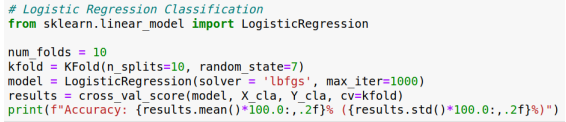


In [5]:
# Logistic Regression Classification
from sklearn.linear_model import LogisticRegression
# En la nueva versión cuando se pone random_state, entonces se tiene que poner shuffle=True

num_folds=10
kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = LogisticRegression(solver = 'lbfgs', max_iter=1000)
results = cross_val_score(model, X_cla, Y_cla, cv=kfold)
print(f"Accuracy: {results.mean()*100.0:.2f}% ({results.std()*100.0:.2f}%)")

Accuracy: 77.61% (3.75%)


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`LogisticRegression`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
</div>

<a id="section212"></a>
### <font color="#004D7F"> 2.1.2. Linear Discriminant Analysis</font>

Linear Discriminant Analysis (LDA) es una técnica estadística para la clasificación binaria y multiclase. También supone una distribución gaussiana para las variables de entrada numéricas. Puede construir un modelo LDA utilizando la clase `LinearDiscriminantAnalysis`.

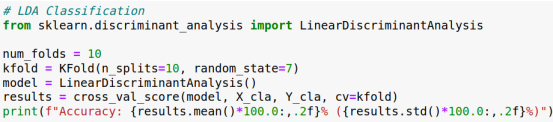

In [6]:
# LDA Classification
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

num_folds=10
kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = LinearDiscriminantAnalysis()
results = cross_val_score(model, X_cla, Y_cla, cv=kfold)
print(f"Accuracy: {results.mean()*100.0:.2f}% ({results.std()*100.0:.2f}%)")

Accuracy: 77.48% (3.69%)


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`LinearDiscriminantAnalysis`](http://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html).
</div>

<a id="section22"></a>
## <font color="#004D7F"> 2.2. Algoritmos de taxonomía no lineal</font>

En este caso vamos a estudiar cuatro algoritmos de Machine Learning no lineales:
* _k_-Nearest Neighbors ($k$-NN).
* Naive Bayes (NB).
* Classification and Regression Trees (CART).
* Support Vector Machines (SVM).

<a id="section221"></a>
### <font color="#004D7F"> 2.2.1. $k$-Nearest Neighbours</font>

El algoritmo $k$-Nearest Neighbours _($k$-NN)_ utiliza una métrica de distancia para encontrar las k instancias más similares en los datos de entrenamiento para una nueva instancia y toma el resultado medio de los vecinos como la predicción. Puede construir un modelo $k$-NN utilizando la clase `KNeighborsClassifier`.

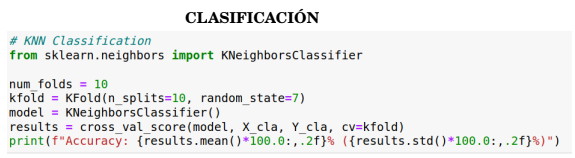

In [7]:
# KNN Classification
from sklearn.neighbors import KNeighborsClassifier

kfold = KFold(n_splits=10, random_state=7, shuffle=True)
num_folds = 10
kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = KNeighborsClassifier()
results = cross_val_score(model, X_cla, Y_cla, cv=kfold)
print(f"Accuracy: {results.mean()*100.0:.2f}% ({results.std()*100.0:.2f}%)")

Accuracy: 86.06% (4.00%)


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`KNeighborsClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html).
</div>

<a id="section222"></a>
### <font color="#004D7F"> 2.2.2. Naive Bayes</font>

Naive Bayes (NB) calcula la probabilidad de cada clase y la probabilidad condicional de cada clase dado cada valor de entrada. Estas probabilidades se estiman para datos nuevos y se multiplican juntos, suponiendo que todas sean independientes (una suposición simple o ingenua). Cuando se trabaja con datos de valor real, se supone que una distribución gaussiana estima fácilmente las probabilidades para las variables de entrada utilizando la función de densidad de probabilidad gaussiana. Puedes construir un modelo Naive Bayes usando la clase `GaussianNB`.

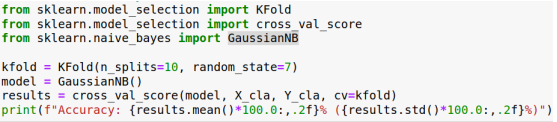


In [8]:
# Gaussian Naive Bayes Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB

kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = GaussianNB()
results = cross_val_score(model, X_cla, Y_cla, cv=kfold)
print(f"Accuracy: {results.mean()*100.0:.2f}% ({results.std()*100.0:.2f}%)")

Accuracy: 76.44% (4.02%)


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`GaussianNB`](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html).
</div>

<a id="section223"></a>
### <font color="#004D7F"> 2.2.3. Classification and Regression Trees</font>

Los árboles de clasificación y regresión (CART) construyen un árbol binario a partir de los datos de entrenamiento. Los puntos divididos se eligen con avidez evaluando cada atributo y cada valor de cada atributo en los datos de entrenamiento para minimizar una función de costo (como el índice de Gini). Puedes construir un modelo CART usando la clase `DecisionTreeClassifier`.

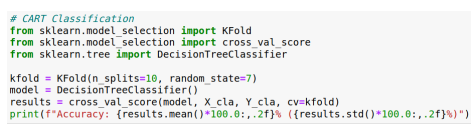

In [9]:
# CART Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = DecisionTreeClassifier()
## También se podría especificar parámetros como indica la clase en sklearn
## En la nueva versión ya no puede ser max_features='sqrt', sino que tiene que ser max_features='sqrt'
#model = DecisionTreeClassifier(criterion='entropy', max_features='sqrt')
results = cross_val_score(model, X_cla, Y_cla, cv=kfold)
print(f"Accuracy: {results.mean()*100.0:.2f}% ({results.std()*100.0:.2f}%)")

Accuracy: 83.86% (5.02%)


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`DecisionTreeClassifier`](http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
</div>

<a id="section224"></a>
### <font color="#004D7F"> 2.2.4. Support Vector Machine</font>

Support Vector Machine (SVM) buscan una línea que separe mejor dos clases. Las instancias de datos más cercanas a la línea que mejor separan las clases se denominan vectores de soporte e influyen en el lugar donde se ubica la línea. SVM se ha extendido para admitir múltiples clases. De particular importancia es el uso de diferentes funciones del núcleo a través del parámetro del núcleo. Por defecto, se utiliza una potente función de base radial. Puedes construir un modelo SVM usando la clase `SVC`.

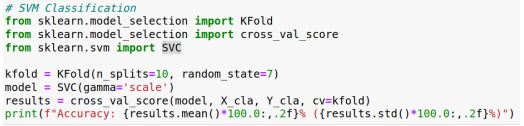


In [10]:
# SVM Classification
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC

kfold = KFold(n_splits=10, random_state=7, shuffle=True)
model = SVC(gamma='scale')
results = cross_val_score(model, X_cla, Y_cla, cv=kfold)
print(f"Accuracy: {results.mean()*100.0:.2f}% ({results.std()*100.0:.2f}%)")

Accuracy: 85.03% (4.73%)


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`SVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).
</div>

<div style="text-align: right"> <font size=5>
    <a href="#indice"><i class="fa fa-arrow-circle-up" aria-hidden="true" style="color:#004D7F"></i></a>
</font></div>

---

<a id="section3"></a>
# <font color="#004D7F"> 3. Algoritmos de Regresión</font>


En esta sección se estudiarán seis algoritmos de Machine Learning que puede usar al verificar su problema de regresión en Python con scikit-learn. Para ello, vamos a echar un vistazo a siete algoritmos de regresión.

<a id="section31"></a>
## <font color="#004D7F"> 3.1. Algoritmos de taxonomía lineal</font>

Comenzamos con cuatro algoritmos lineales:
* Linear Regression (LiR).
* Ridge Regression (RiR).
* LASSO Linear Regression (LASSO).
* Elastic Net Regression (ENR).

<a id="section311"></a>
### <font color="#004D7F"> 3.1.1. Linear Regression</font>

LiR supone que las variables de entrada tienen una distribución gaussiana. También se supone que las variables de entrada son relevantes para la variable de salida y que no están altamente correlacionadas entre sí (un problema llamado colinealidad). Puede construir un modelo de LiR utilizando la clase `LinearRegression`.
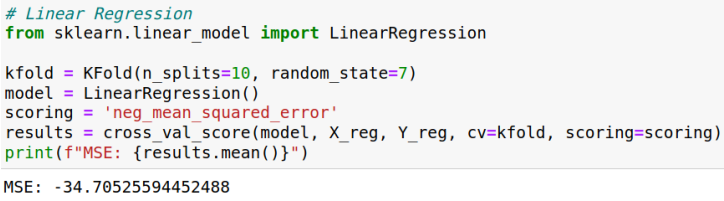

In [12]:
# Linear Regression
from sklearn.linear_model import LinearRegression

kfold= KFold(n_splits=10, random_state=7, shuffle=True)
model = LinearRegression()
scoring = 'neg_mean_squared_error'
results = cross_val_score(model, X_reg, Y_reg, cv=kfold, scoring=scoring)
print(f"Mean Squared Error: {results.mean():.2f} ({results.std():.2f})")

Mean Squared Error: -23.75 (11.14)


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`LinearRegression`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).
</div>

<a id="section312"></a>
### <font color="#004D7F"> 3.1.2. Ridge Regression</font>

RiR es una extensión de LiR donde la función de pérdida se modifica para minimizar la complejidad del modelo medido como el valor de la suma cuadrática de los valores del coeficiente (también llamada norma __L2__). Puede construir un modelo RiR utilizando la clase `Ridge`.

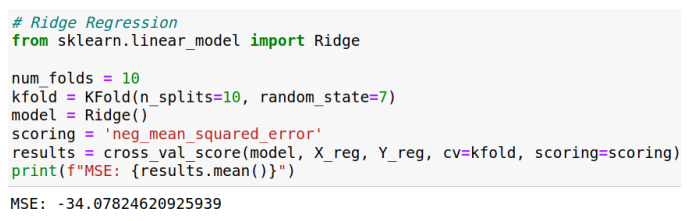

In [13]:
# Ridge Regression
from sklearn.linear_model import Ridge

num_folds=10
kfold= KFold(n_splits=10, random_state=7, shuffle=True)
model = Ridge()
scoring = 'neg_mean_squared_error'
results = cross_val_score(model, X_reg, Y_reg, cv=kfold, scoring=scoring)
print(f"Mean Squared Error: {results.mean():.2f} ({results.std():.2f})")

Mean Squared Error: -23.89 (11.41)


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`Ridge`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).
</div>

<a id="section313"></a>
### <font color="#004D7F"> 3.1.3. LASSO Regression</font>

LASSO es una modificación de LiR, como RiR, donde la función de pérdida se modifica para minimizar la complejidad del modelo medido como el valor absoluto de los valores del coeficiente (también llamada la norma __L1__). Puede construir un modelo LASSO utilizando la clase `Lasso`.

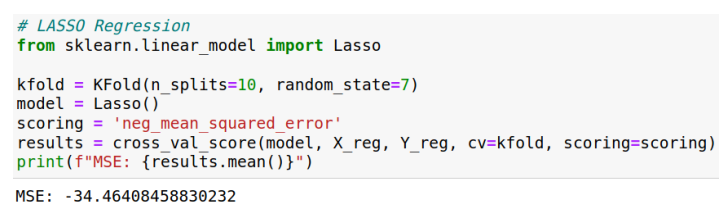

In [14]:
# LASSO Regression
from sklearn.linear_model import Lasso

kfold= KFold(n_splits=10, random_state=7, shuffle=True)
model = Lasso()
scoring = 'neg_mean_squared_error'
results = cross_val_score(model, X_reg, Y_reg, cv=kfold, scoring=scoring)
print(f"Mean Squared Error: {results.mean()}")

Mean Squared Error: -28.74589007585154


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`Lasso`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html).
</div>

<a id="section314"></a>
### <font color="#004D7F"> 3.1.4. ElasticNet Regression</font>

ENR es una forma de regresión de regularización que combina las propiedades de RIR y LASSO. Busca minimizar la complejidad del modelo de regresión (magnitud y número de coeficientes de regresión) penalizando el modelo utilizando tanto la norma L2 (valores de coeficiente de suma cuadrática) como la norma L1 (valores de coeficiente absoluto de suma). Puede construir un modelo ENR utilizando la clase `ElasticNet`.

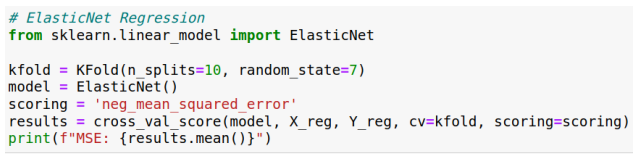

In [15]:
# ElasticNet Regression
from sklearn.linear_model import ElasticNet

kfold= KFold(n_splits=10, random_state=7, shuffle=True)
model = ElasticNet()
scoring = 'neg_mean_squared_error'
results = cross_val_score(model, X_reg, Y_reg, cv=kfold, scoring=scoring)
print(f"Mean Squared Error: {results.mean()}")

Mean Squared Error: -27.90842036023106


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html).
</div>

<a id="section32"></a>
## <font color="#004D7F"> 3.2. Algoritmos de taxonomía no lineal</font>

Posteriormente, estudiaremos tres algoritmos no lineales:
* $k$-Nearest Neighbors ($k$-NN).
* Classification and Regression Trees (CART).
* Support Vector Machines (SVM).

<a id="section321"></a>
### <font color="#004D7F"> 3.2.1. $k$-Nearest Neighbours</font>

$k$-NN localiza las $k$ instancias más similares en el conjunto de datos de entrenamiento para una nueva instancia de datos. De los $k$ vecinos, se toma una variable de salida media o mediana como la predicción. Cabe destacar la métrica de distancia utilizada (el argumento de la métrica). La distancia de _Minkowski_ se usa por defecto, que es una generalización tanto de la distancia euclidiana (utilizada cuando todas las entradas tienen la misma escala) como de la distancia de _Manhattan_ (para cuando las escalas de las variables de entrada difieren). Puede construir un modelo de $k$-NN utilizando la clase `KNeighborsRegressor`.

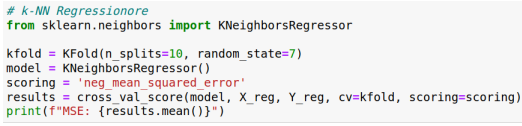

In [16]:
# k-NN Regressionore
from sklearn.neighbors import KNeighborsRegressor

kfold= KFold(n_splits=10, random_state=7, shuffle=True)
model = KNeighborsRegressor()
scoring = 'neg_mean_squared_error'
results = cross_val_score(model, X_reg, Y_reg, cv=kfold, scoring=scoring)
print(f"Mean Squared Error: {results.mean()}")

Mean Squared Error: -38.852320266666666


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`KNeighborsRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html).
</div>

<a id="section322"></a>
### <font color="#004D7F"> 3.2.2. Classification and Regression Trees</font>

CART usa los datos de entrenamiento para seleccionar los mejores puntos para dividir los datos con el fin de minimizar una métrica de costos. La métrica de costo predeterminada para los árboles de decisión de regresión es el error cuadrático medio, especificado en el parámetro `criterion`. Puede construir un modelo CART utilizando la clase `DecisionTreeRegressor`.

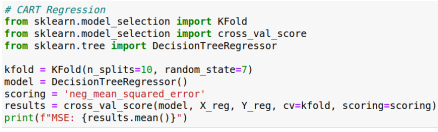

In [17]:
# CART Regression
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor

kfold= KFold(n_splits=10, random_state=7, shuffle=True)
# en la nueva versión criterion='absolute_error' ya no puede ser criterion='mae'
model = DecisionTreeRegressor()
## También se podría especificar parámetros como indica la clase en sklearn
## En la nueva versión criterion='absolute_error' ya no puede ser criterion='mae'
#model = DecisionTreeRegressor(criterion='absolute_error')
scoring = 'neg_mean_squared_error'
results = cross_val_score(model, X_reg, Y_reg, cv=kfold, scoring=scoring)
print(f"Mean Squared Error: {results.mean()}")

Mean Squared Error: -22.62872549019608


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`DecisionTreeRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html).
</div>

<a id="section323"></a>
### <font color="#004D7F"> 3.2.3. Support Vector Machines</font>

SVM se desarrollaró para la clasificación binaria. La técnica se ha extendido para los problemas de predicción de valores reales llamados Support Vector Regression (SVR). Al igual que el ejemplo de clasificación, SVR se basa en la biblioteca `LIBSVM`. Puede construir un modelo SVR utilizando la clase `SVR`.

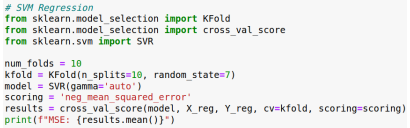

In [18]:
# SVM Regression
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVR

kfold= KFold(n_splits=10, random_state=7, shuffle=True)
model = SVR(gamma='auto')
scoring = 'neg_mean_squared_error'
results = cross_val_score(model, X_reg, Y_reg, cv=kfold, scoring=scoring)
print(f"Mean Squared Error: {results.mean()}")

Mean Squared Error: -83.73272794073159


<div class="alert alert-block alert-info">
    
<i class="fa fa-exclamation-circle" aria-hidden="true"></i>
Documentación oficial de la clase [`SVR`](http://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html).
</div>

<div style="text-align: right"> <font size=5>
    <a href="#indice"><i class="fa fa-arrow-circle-up" aria-hidden="true" style="color:#004D7F"></i></a>
</font></div>

---

<div style="text-align: right"> <font size=6><i class="fa fa-coffee" aria-hidden="true" style="color:#004D7F"></i> </font></div>

# Conclusion
El algoritmo con mejores resultados es KNN -> 86.06 % despues SVM -> 85.03% & Naive Bayes -> 83.86%  (en la parte de CLASIFICACION)
Por otro lado en REGRESION Decision Tree Regressor -> MSE = 22.63, Linear Regression -> MSE = 23.75 & Ridge -> MSE = 23.89 donde MSE => error cuadratico medio, sin embargo eso no significa que siempre estos algoritmos sean los mas efectivos, cada uno tiene un fin y es mas eficiente en cierto contexto 